# Chapitre 1: REGRESSION LINEAIRE

In [9]:
## Importation de la dataset
import warnings
warnings.filterwarnings("ignore")# Masque immédiatement tous les avertissements du code
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.api import add_constant # pour le VIF  
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error 
from sklearn.model_selection import train_test_split                 

#### I- IMPORTATION DE LA DATASET

In [2]:
data=pd.read_csv(r'C:\Users\ELITEBOOK\Documents\EEIA\MED-IA\Cours\Machine_Learning\tp_sante_bodyfat.csv',skiprows=[0],
                 names=["age","DEXfat","waistcirc","hipcirc","elbowbreadth","kneebreadth","anthro3a","anthro3b","anthro3c","anthro4"])
data.head(3)

,age,DEXfat,waistcirc,hipcirc,elbowbreadth,kneebreadth,anthro3a,anthro3b,anthro3c,anthro4
0,57,41.68,100.0,112.0,7.1,9.4,4.42,4.95,4.50,6.13
1,65,43.29,99.5,116.5,6.5,8.9,4.63,5.01,4.48,6.37
2,59,35.41,96.0,108.5,6.2,8.9,4.12,4.74,4.60,5.82


#### II- DESCRIPTION DES VARIABLES DE NOTRE DATASET

| Variable | Type statistique | Signification clinique / Biologique |
| :--- | :--- | :--- |
| **age** | Quantitative | L'âge du patient (en années). |
|**DEXfat**| Quantitative |	La masse grasse corporelle totale (en kg):la variable à prédire.|
|**waistcirc**|	Quantitative| Le tour de taille (waist circumference)|
|**hipcirc**| Quantitative|	Le tour de hanches (hip circumference) |
|**elbowbreadth**| Quantitative| La largeur du coude (elbow breadth)|
|**anthro3a**| Quantitative| Une variable composite basée sur plusieurs mesures|
|**anthro3b**| Quantitative|Une variante de calcul anthropométrique similaire à anthro3a|
|**anthro3c**| Quantitative|Une troisième variante de calcul anthropométrique|
|**anthro4**| Quantitative|Une variable composite combinant quatre mesures anthropométriques.|

#### II- 1 Prendre connaissance de la dataset

In [3]:
# Vérifions si nous avons des doublons dans la dataset
print(f"\n Notre jeu de données comporte: {data.shape[0]} lignes, {data.shape[1]} variables ")
#Prenons connaissance de la natures des variables qui sont dans notre dataset
print(f"\n ============ PRESENTATION DE LA NATURE DES VARIABLES===============\n")
data.info()


 Notre jeu de données comporte: 71 lignes, 10 variables 

 ============ PRESENTATION DE LA NATURE DES VARIABLES===============

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   age           71 non-null     int64  
 1   DEXfat        71 non-null     float64
 2   waistcirc     71 non-null     float64
 3   hipcirc       71 non-null     float64
 4   elbowbreadth  71 non-null     float64
 5   kneebreadth   71 non-null     float64
 6   anthro3a      71 non-null     float64
 7   anthro3b      71 non-null     float64
 8   anthro3c      71 non-null     float64
 9   anthro4       71 non-null     float64
dtypes: float64(9), int64(1)
memory usage: 5.7 KB


##### COMMENTAIRE:
La dataset comporte 10 des variables quantitatives dont la variable cible également.

#### 2- Description de la dataset

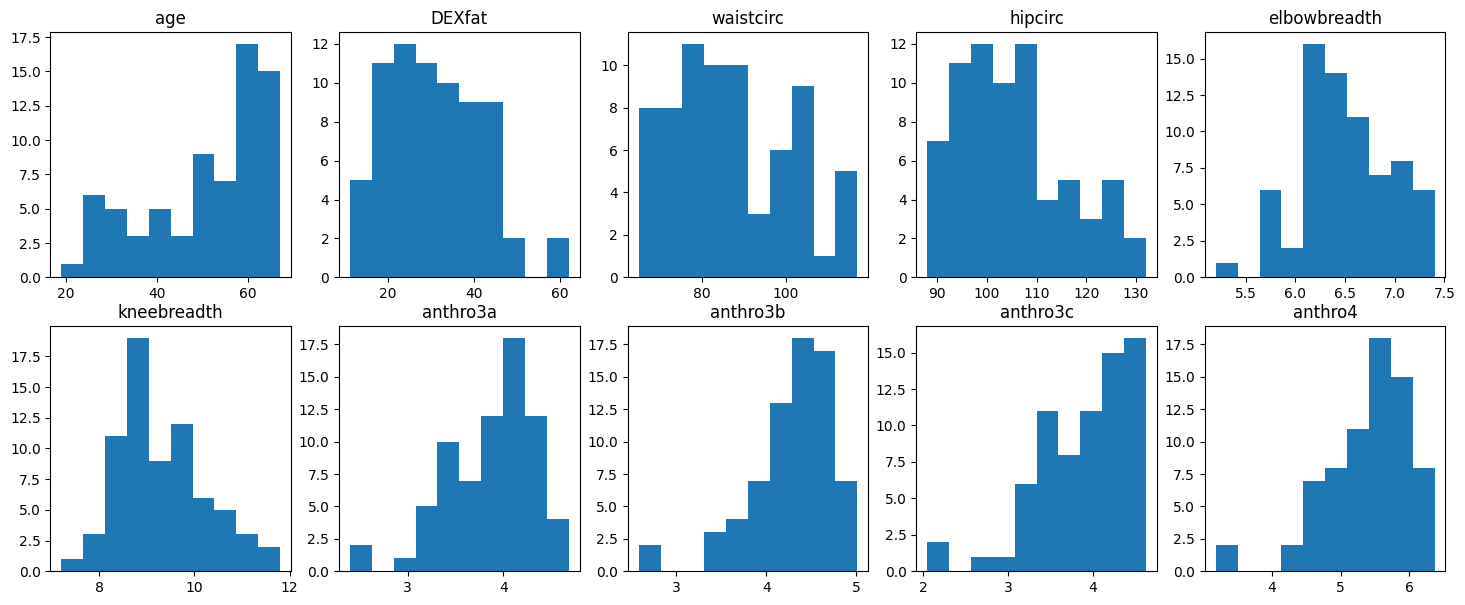

In [4]:
# Création de la grille
fig, axes = plt.subplots(2,5, figsize=(18,7))

for i, col in enumerate(data.columns):
    ax= axes.flatten()[i]
    # On compte les fréquences de chaque catégorie pour créer les barres 
    ax.hist(data[col]) 
    ax.set_title(col)
# Ajustement 
plt.show()

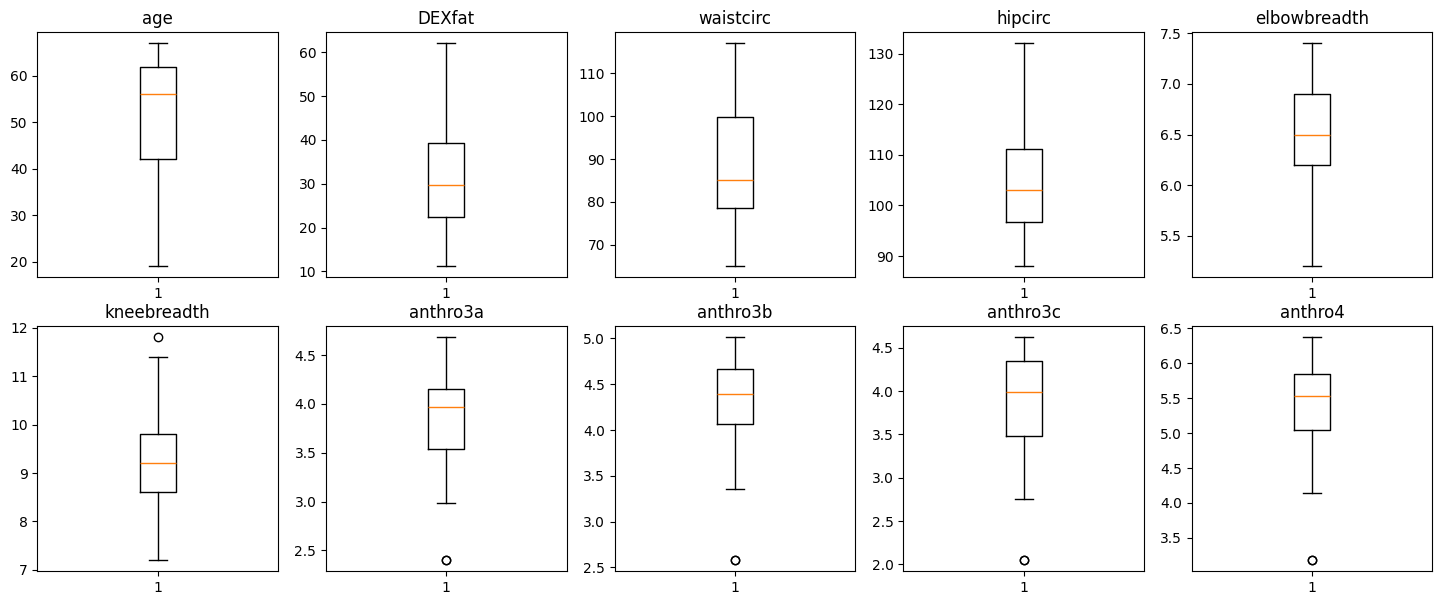

In [24]:
# Création de la grille
fig, axes = plt.subplots(2,5, figsize=(18,7))

for i, col in enumerate(data.columns):
    ax= axes.flatten()[i]
    # On compte les fréquences de chaque catégorie pour créer les barres 
    ax.boxplot(data[col]) 
    ax.set_title(col)
# Ajustement 
plt.show()

## COMMENTAIRE:
Les variables Kneebreadth, anthro3a, anthro3b, anthro3c, anthro4 présentent des valeurs abérrantes à la lecture du boxplot.
On peut aussi voir la distribution de la Target au sein des anthro3b à anthro4 sont stables.

#### MATRICE DE CORRELATION 

========Représentation graphique de la matrice de correlation======


<Axes: >

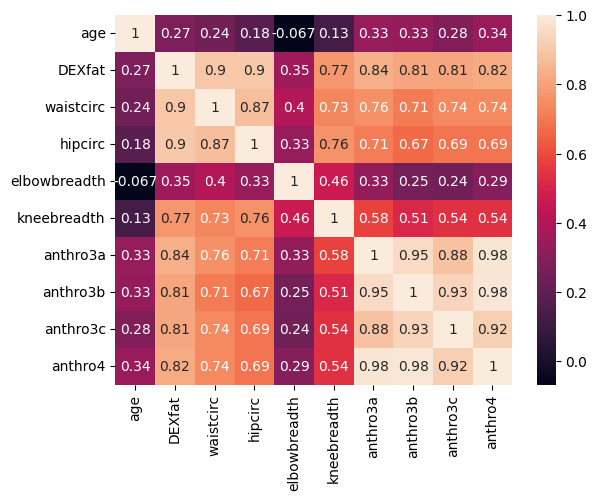

In [5]:
matrice_corr = data.corr(method="pearson")
print("========Représentation graphique de la matrice de correlation======")
sns.heatmap(matrice_corr, annot=True)

### COMMENTAIRE:
- La variable cible est fortement correlée avec waistcirc et hipcirc à hauteur de (90%), avec la variable kneebreath correlée à 0,77 et est correlé à plus de 80% au anthro.
- Les anthro aussi sont fortement correlées entre eux à plus de 80% ; introduire ces 4 anthro dans notre modèle biaisera notre modèle.

### GRAPHIQUE DE L'IMPORTANCE DES VARAIABLES EXPLICATIVES 

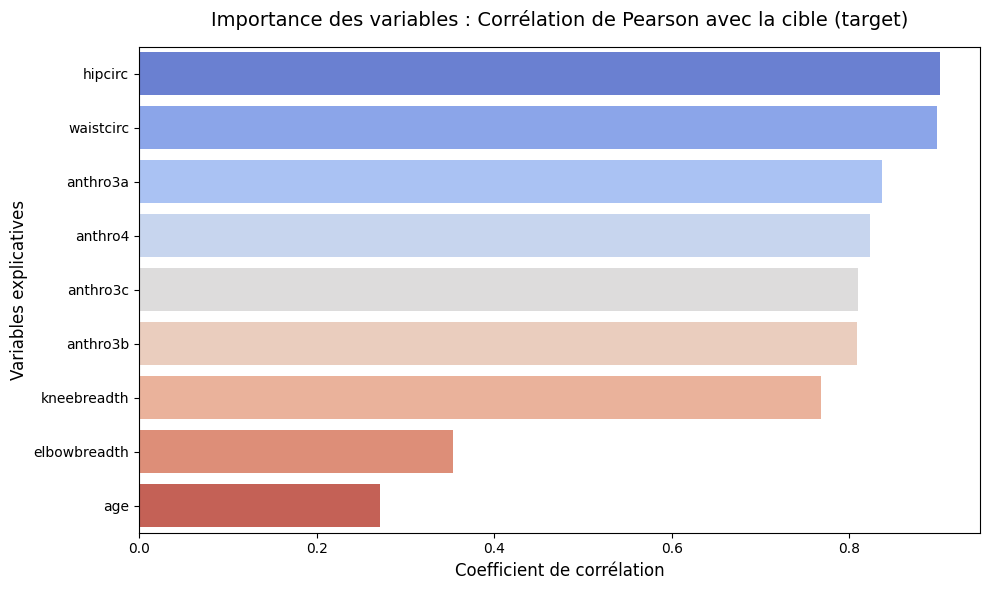

In [10]:
# Isoler la corrélation avec la cible et exclure la cible elle-même (qui vaut 1.0)
corr_avec_cible = matrice_corr['DEXfat'].drop('DEXfat').sort_values(ascending=False)
# Configuration du graphique
plt.figure(figsize=(10, 6))
sns.barplot(
    x=corr_avec_cible.values, 
    y=corr_avec_cible.index, 
    palette="coolwarm")
plt.title("Importance des variables : Corrélation de Pearson avec la cible (target)", fontsize=14, pad=15)
plt.xlabel("Coefficient de corrélation", fontsize=12)
plt.ylabel("Variables explicatives", fontsize=12)
plt.tight_layout()
plt.show()

### COMMENTAIRE
Des deux sorties de graphique de la matrice de correlation,  les variables hipcirc, waistcirc et anthro3a ont les correlation les plus forte avec notre variable cible. On remarque que les variables **hipcirc** et **waistcirc** sont correlées entre elles à hauteur de plus de 80%. Il serait objectif de faire le choix entre une de ses variables pour le modèle de régression linéaire afin d'éviter la multicolinéarité. Vu que la consigne est de choisir les trois meilleures variables explcatives qui explique le modèle, nous allons choisir parmis ces deux celle qui est plus facile à collecter. Aussi les trois variables anthro étant fortement correlées entre elles, nous choisirons que un seul parmi eux. Après ces deux premiers choix la troisième variable est alors la variable **kneebreadth**.

## VERIFIONS LE VIF POUR LES TROIS VARIABLES SELECTIONNEES

In [11]:
var_retenue= data[["waistcirc", "anthro3a", "kneebreadth"]]
var_retenue_cst=add_constant(var_retenue)
############# Calcule du VIF
vif_data=pd.DataFrame()
vif_data["Variable"]= var_retenue.columns
vif_data["VIF"]=[
    variance_inflation_factor(var_retenue_cst.values, i)
    for i in range(1,var_retenue_cst.shape[1])]
print("====== TABLEAU VIF=====")
print(vif_data.round(2))

====== TABLEAU VIF=====
      Variable   VIF
0    waistcirc  3.32
1     anthro3a  2.34
2  kneebreadth  2.16


## COMMENTAIRE: 
Le VIF observé pour les trois variables explicatives est inférieur à 5, ce qui nous amène à conclure
les trois variables retenues pour le modèle ne sont pas redondants. On est en l'absence de multicolinéarité problématique.

## REALISONS LE VIF SUR TOUTES LES VARIABLES EXPLICATIVES
Pour voir que passer directement au VIF, nous permet pas de faire des choix objectifs

In [12]:
var_retenue= data[['age','waistcirc', 'hipcirc', 'elbowbreadth', 'kneebreadth',
       'anthro3a', 'anthro3b', 'anthro3c', 'anthro4']]
var_retenue_cst=add_constant(var_retenue)
############# Calcule du VIF
vif_data=pd.DataFrame()
vif_data["Variable"]= var_retenue.columns
vif_data["VIF"]=[
    variance_inflation_factor(var_retenue_cst.values, i)
    for i in range(1,var_retenue_cst.shape[1])]
print("====== TABLEAU VIF=====")
print(vif_data.round(2))

====== TABLEAU VIF=====
       Variable     VIF
0           age    1.21
1     waistcirc    5.77
2       hipcirc    5.12
3  elbowbreadth    1.42
4   kneebreadth    2.85
5      anthro3a   39.47
6      anthro3b   49.10
7      anthro3c    9.04
8       anthro4  111.26


## COMMENTAIRE 
Le VIF de anthro4 nous montre clairement que cette information est fortement correlée avec les autres anthro qui sont reliées entre elles.
Les variables comme age, elbowbreadth présentent un très bon VIF. Mais si on avait pas fait la correlation entre la cible et les variables explicatives, on les auraient choisies aveuglément alors que ces dernières n'ont pas de lien tangible avec la cible.
Conclusion: Faire la corrélation entre la target et les variables explicatives est la première chose primordiale à faire en analyse de données.

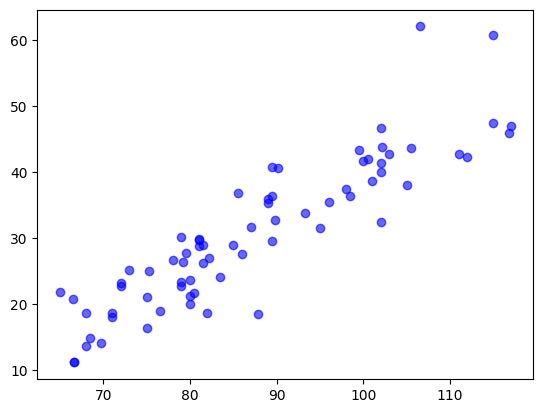

In [41]:

################
plt.scatter(
     data[["waistcirc"]], data["DEXfat"], color="blue", alpha=0.6, label="Représentation graphique"
)

### PREPARATION DU JEU DE DONNEES

In [14]:
#  Définition de la variable explicative (X) et de la cible (y)
# Note : X doit être un tableau à deux dimensions (DataFrame), d'où les doubles crochets [[]]
X = data[["waistcirc"]]
X_1 = data[["waistcirc","anthro3a","kneebreadth"]]
y = data["DEXfat"]

# 3. Séparation des données : 80% pour l'entraînement (Train) et 20% pour le test (Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
###########
X_train1, X_test1, y_train1, y_test = train_test_split(
    X_1, y, test_size=0.2, random_state=42
)

In [15]:
# 4. Création et entraînement du modèle de régression linéaire
modele_lin = LinearRegression()
modele_lin.fit(X_train, y_train)

# 5. Réalisation des prédictions sur l'échantillon de test
y_pred = modele_lin.predict(X_test)

# 6. Évaluation du modèle
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae= mean_absolute_error(y_test, y_pred)
print("--- ÉVALUATION DE LA RÉGRESSION LINÉAIRE ---")
print(f"Coefficient de détermination (R²) : {r2:.2f}")
print(f"Erreur quadratique moyenne (RMSE) : {rmse:.2f} points")
print(f"Erreur quadratique moyenne (MAE) : {mae:.2f} points")

--- ÉVALUATION DE LA RÉGRESSION LINÉAIRE ---
Coefficient de détermination (R²) : 0.81
Erreur quadratique moyenne (RMSE) : 3.81 points
Erreur quadratique moyenne (MAE) : 2.92 points


## COMMENTAIRE
- Les informations contenues dans DEXfat sont expliquées à haut de 81% par la variable explicatives waistcirc.
- La moyenne de la variable cible DEXFact étant d'environ 30, les valeurs obtenues pour la rmse et le mae sont très petites on peut alors dire que notre modèle est globalement bon.

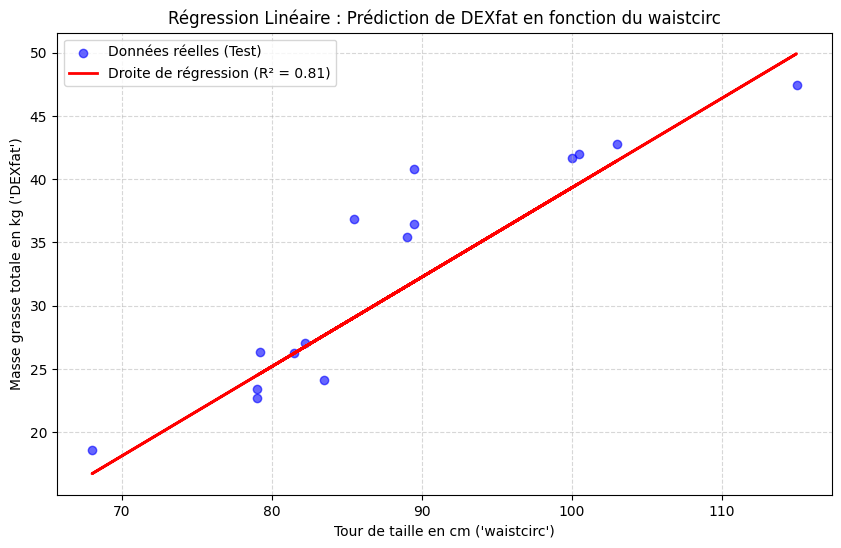

In [22]:
# 7. Visualisation graphique de la droite de régression
plt.figure(figsize=(10, 6))
plt.scatter(
    X_test, y_test, color="blue", alpha=0.6, label="Données réelles (Test)"
)
plt.plot(
    X_test,
    y_pred,
    color="red",
    linewidth=2,
    label=f"Droite de régression (R² = {r2:.2f})",
)
plt.title("Régression Linéaire : Prédiction de DEXfat en fonction du waistcirc")
plt.xlabel("Tour de taille en cm ('waistcirc')")
plt.ylabel("Masse grasse totale en kg ('DEXfat')")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## REGRESSION MULTIPLE AVEC LES TROIS VARIABLES EXPLICATIVES

In [17]:
modele_multiple = smf.ols("DEXfat ~ waistcirc + anthro3a + kneebreadth ", data=data).fit()
print(modele_multiple.summary())

                            OLS Regression Results                            
Dep. Variable:                 DEXfat   R-squared:                       0.887
Model:                            OLS   Adj. R-squared:                  0.882
Method:                 Least Squares   F-statistic:                     175.6
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           1.12e-31
Time:                        20:07:55   Log-Likelihood:                -193.31
No. Observations:                  71   AIC:                             394.6
Df Residuals:                      67   BIC:                             403.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept     -57.9146      5.175    -11.192      

### INTERPRETATION DE LA SORTIE DE LA REGRESSION MULTIPLE

Les informations contenues dans **DEXfat** sont expliquées à hauteur de 88% par les trois variables explicatives sélectionnées (waistcirc, anthro3a et kneebreadth)

**Intercept (-57.9146)**: C'est la valeur constante de DEXfat quand toutes les variables explkcatives sont égales à zéro.

**waistcirc (0.3737)**: Une augmentation d'une unité de waistcirc entraine une augmentation de 0.3737 unité de DEXfat, toute choses étant égale par ailleurs.

**anthro3a (8.2430)**: Une augmentation d'une unité de anthro3a entraine une augmentation de 8.2430  unité de DEXfat, toute choses étant égale par ailleurs.

**kneebreadth (2.5964)**: Une augmentation d'une unité de kneebreadth  entraine une augmentation de 2.5964 unité de DEXfat, toute choses étant égale par ailleurs.

#### MODELE DE REGRESSION AVEC DEUX VARIABLES EXPLICATIVES

In [21]:
# Selection de deux variables
X_1 = data[["waistcirc", "anthro3a", "kneebreadth"]]
###########
X_train1, X_test1, y_train1, y_test = train_test_split(
    X_1, y, test_size=0.2, random_state=42
)
modele_lin.fit(X_train1, y_train1)
y_pred1 = modele_lin.predict(X_test1)# Le modèle avec deux variaables
# 6. Évaluation du modèle
r2_1 = r2_score(y_test, y_pred1)
rmse_1 = np.sqrt(mean_squared_error(y_test, y_pred1))
mae_1 = (mean_absolute_error(y_test, y_pred1))

print("--- ÉVALUATION DE LA RÉGRESSION LINÉAIRE ---")
print(f"Coefficient de détermination (R²) : {r2_1:.2f}")
print(f"Erreur quadratique moyenne (RMSE) : {rmse_1:.2f} points")
print(f"Erreur moyenne absolue (MAE) : {mae_1:.2f} points")
print(f"Équation du plan : y = {modele_multiple.params['waistcirc']:.2f} * waistcirc + {modele_multiple.params['anthro3a']:.2f} * anthro3a + {modele_multiple.params['kneebreadth']:.2f} * kneebreadth + {modele_multiple.params['Intercept']:.2f}")

--- ÉVALUATION DE LA RÉGRESSION LINÉAIRE ---
Coefficient de détermination (R²) : 0.90
Erreur quadratique moyenne (RMSE) : 2.81 points
Erreur moyenne absolue (MAE) : 2.12 points
Équation du plan : y = 0.37 * waistcirc + 8.24 * anthro3a + 2.60 * kneebreadth + -57.91


<span style="color:navy">**NOTE MÉTHODOLOGIQUE**:</span>            

**Pourquoi observe-t-on une différence de $(R^{2})$ entre Statsmodels $(0.89)$ et Scikit-Learn $(0.90)$?**

En analysant les sorties, vous remarquerez que le coefficient de détermination $(R^{2})$ n'est pas strictement identique entre nos deux analyses :

• Statsmodels (R^{2} = 0.89) : Ce modèle est ajusté sur l'intégralité de la cohorte $(71)$ patients. Il décrit la **performance théorique globale des variables au sein de notre échantillon d'étude**.

• Scikit-Learn $(R^2 = 0.90)$ : Ce score est calculé uniquement sur l'échantillon Test (les $(20 %)$) de patients volontairement mis de côté). Il mesure **le véritable pouvoir prédictif du modèle**, c'est-à-dire sa capacité à estimer correctement la masse grasse chez de nouveaux patients virtuels dont le modèle n'a pas vu les données durant son entraînement.

<span style="color:navy">**BON A SAVOIR**:</span>            

<span style="color:navy">**Statsmodels :**</span> L'approche Épidémiologique & Explicative

**• Objectif** : Comprendre et Expliquer les mécanismes de la population étudiée.

**• Philosophie** : C'est l'outil du chercheur. Il analyse l'ensemble des données passées pour valider scientifiquement des liens de cause à effet.

**• Indicateurs clés fournis :** Les $(p-values)$ (pour éliminer le hasard), les intervalles de confiance, et le VIF (pour détecter la redondance des mesures cliniques).


<span style="color:navy">**Scikit-Learn:**</span> L'approche Machine Learning & Prédictive

**• Objectif :** Prédire et Anticiper l'état de futurs patients.

**• Philosophie :** C'est l'outil du clinicien ou de l'application d'aide au diagnostic. Il se focalise sur la précision des résultats futurs, peu importe la complexité des formules internes.